In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import scipy.stats as st

In [ ]:
# calculate transition probabilities
import pandas as pd

data = pd.read_csv('labeled_data_3000-6000.csv')
df = pd.DataFrame(data)

# Encoding label names
label_encoding = {
    'Follow_behind': 2,
    'Slow_down': 4,
    'Catch_up': 0,
    'Speed_up': 3,
    'Fall_behind': 1,
    'Hold_speed': 5
}

# Define a function to calculate durations
def calculate_durations(points):
    return [int(points[i+1]) - int(points[i]) for i in range(len(points)-1)]

# Initialize lists to store encoded label sequences and duration sequences
encoded_labels = []
durations = []
for _, row in df.iterrows():
    label_sequence = []
    labels = eval(row['Label'])
    for label in labels[1:]:
        if label in label_encoding:
            label_sequence.append(label_encoding[label])
        else:
            print(f"Warning: Label '{label}' not found in label encoding dictionary.")
    
    duration_sequence = calculate_durations(eval(row['Point']))
    
    encoded_labels.append(label_sequence)
    durations.append(duration_sequence)
print(encoded_labels)
# Convert the lists to NumPy arrays
encoded_labels = np.array(encoded_labels, dtype=object)
durations = np.array(durations,dtype=object)

for i in range(min(3, len(encoded_labels))):  # Print data for the first three drivers or less if there are fewer drivers
    print(f"Driver {i+1}:")
    print("  Encoded label sequence:", encoded_labels[i])
    print("  Duration sequence:", durations[i])

from collections import Counter

# Flattened count of each label
flat = [lab for seq in encoded_labels for lab in seq]
label_counts = Counter(flat)
print("Label frequencies:")
for lab, cnt in sorted(label_counts.items()):
    print(f"  {lab}: {cnt}")

# Count of each transition (adjacent pair)
transitions = Counter(
    (seq[i], seq[i+1])
    for seq in encoded_labels
    for i in range(len(seq)-1)
)
print("\nTransition counts:")
for (a, b), cnt in sorted(transitions.items()):
    print(f"  {a} → {b}: {cnt}")

# 1) Count all transitions (a → b)
transitions = Counter(
    (a, b)
    for seq in encoded_labels
    for a, b in zip(seq, seq[1:])
)

# 2) Compute incoming counts for each target state b
incoming_counts = Counter()
for (a, b), cnt in transitions.items():
    incoming_counts[b] += cnt

# 3) Print results
print("Incoming transition counts (→ b):")
for b, cnt in sorted(incoming_counts.items()):
    print(f"  → {b}: {cnt}")

[[2, 0, 2], [2, 2, 2, 1, 2], [2, 1, 2, 5], [4, 1, 1], [3, 1, 1], [4, 4], [4, 4, 4], [3, 3], [1, 1], [2, 1, 1], [1, 0, 2], [2, 2, 0, 4, 4], [2, 4, 4], [2, 2, 1, 4, 4], [1, 1, 4, 1], [5, 5, 1, 0, 4, 4], [3, 2, 2], [4, 3, 4, 4, 2], [3, 2, 2, 5], [1, 3, 3], [4, 1, 2, 5], [3, 3, 5], [3, 0, 0], [2, 2, 1], [3, 3, 5], [3, 3], [2, 5, 5, 5, 5], [2, 0, 2, 2, 2, 5], [4, 3, 2, 2, 2], [3, 4, 4], [5, 5, 2, 2], [2, 0, 4, 4], [2, 2, 0, 0, 0], [5, 0, 4, 2, 1], [4, 0, 0], [3, 1, 1], [0, 0, 0], [0, 4, 4], [1, 3, 1, 1], [4, 1], [3, 3, 1, 1], [3, 2, 2, 2, 2, 2], [5, 5, 5, 5, 5, 5, 1, 1], [0, 4, 4], [2, 2, 2, 1, 1], [0, 3, 3, 2, 5, 5], [2, 2, 2, 1, 1], [3, 4, 3, 3], [2, 1, 5], [4, 0, 0], [4, 2, 2], [4, 0, 4, 4], [4, 3, 3], [1], [4, 5], [1, 0, 0], [1, 0, 1, 5, 5], [2, 2, 1, 1], [0, 2], [3, 0, 2, 2, 2, 0, 0], [1, 1, 3, 1, 1], [4, 3, 3], [3, 3], [4, 3, 3], [3, 5], [1, 0, 5, 5], [2, 0, 1, 2, 2], [4, 2, 0, 0], [4, 2, 2, 1], [2, 5], [2, 1, 1], [4, 4, 3, 1], [3, 2, 2], [0, 4, 3, 2], [1, 3, 2, 2, 0, 4, 1, 1, 2], [1,

In [86]:
def adjust_transitions(base_transitions, lambda_heterogeneity):
    adjusted_transitions = {}
    for current_state, transitions in base_transitions.items():
        # Extract original follow_behind probability and other probabilities
        primary_prob = transitions["follow_behind"]
        num_other_states = len(transitions) - 1
        
        # Redistribute probabilities
        adjusted_primary_prob = primary_prob * (1 - lambda_heterogeneity)
        redistributed_prob = (1 - adjusted_primary_prob) / num_other_states
        
        # Adjusted transition dictionary
        adjusted_transitions[current_state] = {}
        for next_state in transitions:
            if next_state == "follow_behind":
                adjusted_transitions[current_state][next_state] = adjusted_primary_prob
            else:
                adjusted_transitions[current_state][next_state] = redistributed_prob

    return adjusted_transitions

# Heterogeneous traffic flow simulation

Simulation complete: 0 collisions detected.
Total VSP: 5251.94
Average TTC: 17453370680093.164 s
Average TET: inf s (count=0)


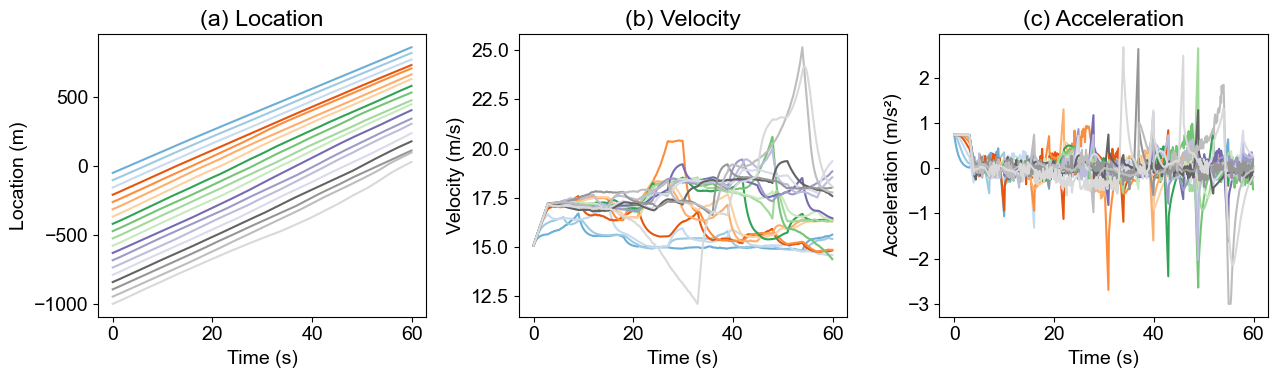

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm

plt.rc('font', family='Arial', size=14)

# --- 1) Empirical base transition matrix & flatten to P_base ---
base_transitions = {
    "catch_up":      {"follow_behind": 0.2572, "catch_up": 0.1255, "fall_behind": 0.1383, "speed_up": 0.1152, "slow_down": 0.2578, "hold_speed": 0.1060},
    "fall_behind":   {"follow_behind": 0.2945, "catch_up": 0.1170, "fall_behind": 0.1481, "speed_up": 0.2623, "slow_down": 0.0644, "hold_speed": 0.1137},
    "follow_behind": {"follow_behind": 0.3902, "catch_up": 0.1313, "fall_behind": 0.1560, "speed_up": 0.1207, "slow_down": 0.0899, "hold_speed": 0.1119},
    "speed_up":      {"follow_behind": 0.2622, "catch_up": 0.1927, "fall_behind": 0.1861, "speed_up": 0.1481, "slow_down": 0.1324, "hold_speed": 0.0786},
    "slow_down":     {"follow_behind": 0.2148, "catch_up": 0.1274, "fall_behind": 0.1785, "speed_up": 0.3119, "slow_down": 0.0704, "hold_speed": 0.0970},
    "hold_speed":    {"follow_behind": 0.2911, "catch_up": 0.1337, "fall_behind": 0.1337, "speed_up": 0.1017, "slow_down": 0.0884, "hold_speed": 0.2514}
}
all_patterns = list(base_transitions.keys())

def make_base_matrix(trans_dict, patterns):
    P = np.zeros((len(patterns), len(patterns)))
    for i, pi in enumerate(patterns):
        for j, pj in enumerate(patterns):
            P[i, j] = trans_dict[pi][pj]
    return P

P_base = make_base_matrix(base_transitions, all_patterns)

# --- 2) Pattern‐specific duration Gaussians D(μ,σ) ---
base_dur_mu = {
    "follow_behind": 3.0, "catch_up": 3.0, "fall_behind": 3,
    "speed_up": 3,     "slow_down": 3,  "hold_speed": 3.0
}
sigma = 0.0
base_dur_sigma = {
    "follow_behind": sigma, "catch_up": sigma, "fall_behind": sigma,
    "speed_up":      sigma, "slow_down": sigma, "hold_speed": sigma
}

# --- 3) Generate driver‐phases: heterogeneous Dir(lambda·P_base) + Gaussian durations ---
def generate_driver_phases(num_vehicles, total_time, lambda_concentration, min_dur=0.1):
    driver_phases = {}
    driver_probs  = {}
    for m in range(num_vehicles):
        patterns, durations, probs = [], [], []
        t_acc, prev = 0.0, all_patterns[0]

        # first phase = follow_behind
        patterns.append(prev)
        d0 = max(np.random.normal(base_dur_mu[prev], base_dur_sigma[prev]), min_dur)
        durations.append(d0)
        probs.append(np.eye(len(all_patterns))[0])  # one‐hot
        t_acc += d0

        while t_acc < total_time:
            # sample driver‐specific transition matrix
            P_m = np.vstack([
                np.random.dirichlet(lambda_concentration * P_base[i])
                for i in range(len(all_patterns))
            ])
            row = P_m[all_patterns.index(prev)]
            nxt = np.random.choice(all_patterns, p=row)

            # sample duration for nxt
            mu, sigma = base_dur_mu[nxt], base_dur_sigma[nxt]
            dur = max(np.random.normal(mu, sigma), min_dur)

            patterns.append(nxt)
            durations.append(dur)
            probs.append(row)

            t_acc += dur
            prev  = nxt

        driver_phases[m] = {'patterns': patterns, 'durations': durations}
        driver_probs [m] = np.vstack(probs)

    return driver_phases, driver_probs

# --- 4) Simulation w/ smoothing across pattern changes ---
def simulate_traffic_flow(cfg):
    N = cfg['num_vehicles']
    pos0, vel0 = cfg['initial_positions'], cfg['initial_velocities']
    T, L, dt = cfg['total_time'], cfg['vehicle_length'], cfg['delta_t']
    lam = cfg['lambda_concentration']
    min_dur, trans_t = cfg['min_duration'], cfg['transition_time']
    K = max(int(np.ceil(trans_t / dt)), 1)

    phases, probs_dict = generate_driver_phases(N, T, lam, min_dur)
    vehicles = [{
        'id':i, 'pos':pos0[i], 'vel':vel0[i], 'acc':0.0,
        'last_pattern': all_patterns[0], 'trans_steps':0,
        'a_prev':0.0, 'a_target':0.0
    } for i in range(N)]

    records = []; collisions = 0; t = 0.0

    def get_pattern(m, tc):
        cum = np.cumsum(phases[m]['durations'])
        idx = np.searchsorted(cum, tc)
        return phases[m]['patterns'][ min(idx, len(cum)-1) ]

    while t < T:
        prev_pos = [v['pos'] for v in vehicles]
        prev_vel = [v['vel'] for v in vehicles]
        for i, v in enumerate(vehicles):
            pat = get_pattern(i, t)
            # compute a_new, v_new, x_new exactly as before
            if i == 0:
                a_new, v_new = 0.0, max(v['vel'],5)
                x_new = v['pos'] + v_new*dt
            else:
                s = max(prev_pos[i-1] - prev_pos[i] - L, 0.1)
                dv = prev_vel[i-1] - prev_vel[i]
                if pat in ['speed_up','slow_down']:
                    raw = (2.28/np.sqrt(s)-0.19)*dv + np.random.normal(0,0.1)
                    a_new = np.clip(-1*raw, -3, 3)
                    v_new = max(v['vel'] + a_new*dt, 5)
                    x_new = prev_pos[i] + v_new*dt + 0.5*(15-v_new)*10*(dt**2)
                elif pat=='hold_speed':
                    a_new = np.random.normal(0,0.1)
                    v_new = max(v['vel'] + a_new*dt, 5)
                    x_new = prev_pos[i] + v_new*dt + 0.5*(15-v_new)*10*(dt**2)
                elif pat=='catch_up':
                    Kc,ac,st = (-0.0266,1.06,20)
                    a_new = np.clip(Kc*(st-s)+ac*dv, -3, 3)
                    v_new = max(v['vel'] + a_new*dt, 0)
                    x_new = prev_pos[i] + v_new*dt
                elif pat=='fall_behind':
                    Kf,af,st = (0.0093,0.9144,30)
                    a_new = np.clip(Kf*(st-s)+af*dv, -3, 3)
                    v_new = max(v['vel'] + a_new*dt, 0)
                    x_new = prev_pos[i] + v_new*dt
                else:  # follow_behind
                    Kfb,afb,sd = (-0.0045,0.927,40)
                    a_new = np.clip(Kfb*(sd-s)+afb*dv, -3, 3)
                    v_new = max(v['vel'] + a_new*dt, 0)
                    x_new = prev_pos[i] + v_new*dt
                if x_new >= prev_pos[i-1]:
                    collisions += 1

            # smoothing on pattern change
            if pat != v['last_pattern']:
                v['trans_steps'] = K
                v['a_prev'] = v['acc']
                v['a_target'] = a_new
            if v['trans_steps'] > 0:
                k = K - v['trans_steps']
                a = (1 - k/K)*v['a_prev'] + (k/K)*v['a_target']
                v['trans_steps'] -= 1
            else:
                a = a_new

            records.append({
                'vehicle_id':i,
                'time':round(t,4),
                'pattern':pat,
                'acceleration':a,
                'velocity':v_new,
                'position':x_new
            })
            v.update({'pos':x_new,'vel':v_new,'acc':a,'last_pattern':pat})
        t += dt

    return pd.DataFrame(records), phases, probs_dict, collisions

# --- 5) Metric calculation ---
def calculate_average_ttc(df, N, vehicle_length=5.0, delta_t=0.1):
    ttc_values, tet_values = [], []
    total_vsp, tet_count = 0, 0
    for vid in range(1, N):
        veh = df[df['vehicle_id']==vid]
        lead= df[df['vehicle_id']==vid-1]
        for t in veh['time'].unique():
            vrow = veh[veh['time']==t].iloc[0]
            lrow = lead[lead['time']==t]
            if lrow.empty: continue
            l = lrow.iloc[0]
            x_i, v_i, a_i = vrow['position'], vrow['velocity'], vrow['acceleration']
            x_l, v_l = l['position'], l['velocity']
            total_vsp += (0.132*v_i + 1.1*v_i*a_i + 0.0003202*v_i**3)*delta_t
            dv = v_i - v_l
            if dv < 0:
                ttc = (x_l - x_i - vehicle_length)/(-dv)
                ttc_values.append(ttc)
                if 0 <= ttc <= 2:
                    tet_values.append(ttc); tet_count+=1
    return (total_vsp,
            np.mean(ttc_values) if ttc_values else np.inf,
            np.mean(tet_values) if tet_values else np.inf,
            tet_count)

def plot_summary(df, probs_dict, patterns, dt, filename=None):
    """
    Draw a 2×2 figure showing:
     (a) violin of transition probabilities for one random driver
     (b) positions over time
     (c) velocities over time
     (d) accelerations over time
    """
    abbr = {
        "follow_behind": "FL",
        "catch_up":      "CU",
        "fall_behind":   "FB",
        "speed_up":      "SU",
        "slow_down":     "SD",
        "hold_speed":    "HS",
    }
    N = len(probs_dict)
    driver = np.random.choice(list(probs_dict.keys()))
    fig, axs = plt.subplots(1,3, figsize=(14,4))
    
    # (b) positions
    ax = axs[0]
    cmap = cm.get_cmap('tab20c', N)
    for vid in range(1,N):
        sub = df[df['vehicle_id']==vid]
        ax.plot(sub['time'], sub['position'], color=cmap(vid), alpha=1)
    ax.set_xlabel('Time (s)'); ax.set_ylabel('Location (m)')
    ax.set_title("(a) Location")
    
    # (c) velocities
    ax = axs[1]
    for vid in range(1,N):
        sub = df[df['vehicle_id']==vid]
        ax.plot(sub['time'], sub['velocity'], color=cmap(vid), alpha=1)
    ax.set_xlabel('Time (s)'); ax.set_ylabel('Velocity (m/s)')
    ax.set_title("(b) Velocity")
    
    # (d) accelerations
    ax = axs[2]
    for vid in range(1,N):
        sub = df[df['vehicle_id']==vid]
        ax.plot(sub['time'], sub['acceleration'], color=cmap(vid), alpha=1)
    ax.set_xlabel('Time (s)'); ax.set_ylabel('Acceleration (m/s²)')
    ax.set_title("(c) Acceleration")

    # # (d) violin for random driver
    # ax = axs[1,1]
    # data = [probs_dict[driver][:,i] for i in range(len(patterns))]
    # parts = ax.violinplot(data, showmedians=True)
    # for pc in parts['bodies']:
    #     pc.set_facecolor('#8FB9A8'); pc.set_edgecolor('black'); pc.set_alpha(0.7)
    # parts['cmedians'].set_edgecolor('black'); parts['cmedians'].set_linewidth(2)

    # ax.set_xticks(np.arange(1, len(patterns)+1))
    # ax.set_xticklabels([abbr[p] for p in patterns], rotation=0)
    # ax.set_ylabel('Transition probability at each phase')
    # ax.set_title(f"(d) Statistics of Driver {driver}")
    
    fig.tight_layout()
    if filename:
        fig.savefig(filename, dpi=300, bbox_inches='tight')
    plt.show()


if __name__ == "__main__":
    base_config = {
        'num_vehicles': 20,
        'initial_positions': np.linspace(0, -1000, 20),
        'initial_velocities': np.full(20, 15),
        'total_time': 60,
        'vehicle_length': 5.0,
        'delta_t': 0.1,
        'lambda_concentration': 10,
        'mu_duration': 4.0,
        'sigma_duration': 0.0,
        'min_duration': 0.5,
        'transition_time': 1.0
    }
    # … your base_config, simulation, metrics, etc. …
    df, phases, probs, total_coll = simulate_traffic_flow(base_config)
    total_vsp, avg_ttc, avg_tet, tet_count = calculate_average_ttc(
        df, base_config['num_vehicles'],
        vehicle_length=base_config['vehicle_length'],
        delta_t=base_config['delta_t']
    )
    print(f"Simulation complete: {total_coll} collisions detected.")
    print(f"Total VSP: {total_vsp:.2f}")
    print(f"Average TTC: {avg_ttc:.3f} s")
    print(f"Average TET: {avg_tet:.3f} s (count={tet_count})")
    
    # draw summary figure
    plot_summary(
        df, 
        probs, 
        all_patterns, 
        dt=base_config['delta_t'],
        filename=f"summary_lambda_{base_config['lambda_concentration']}.pdf"
    )

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm

plt.rc('font', family='Arial', size=14)

# --- 1) Empirical base transition matrix & flatten to P_base ---
base_transitions = {
    "catch_up":      {"follow_behind": 0.2572, "catch_up": 0.1255, "fall_behind": 0.1383, "speed_up": 0.1152, "slow_down": 0.2578, "hold_speed": 0.1060},
    "fall_behind":   {"follow_behind": 0.2945, "catch_up": 0.1170, "fall_behind": 0.1481, "speed_up": 0.2623, "slow_down": 0.0644, "hold_speed": 0.1137},
    "follow_behind": {"follow_behind": 0.3902, "catch_up": 0.1313, "fall_behind": 0.1560, "speed_up": 0.1207, "slow_down": 0.0899, "hold_speed": 0.1119},
    "speed_up":      {"follow_behind": 0.2622, "catch_up": 0.1927, "fall_behind": 0.1861, "speed_up": 0.1481, "slow_down": 0.1324, "hold_speed": 0.0786},
    "slow_down":     {"follow_behind": 0.2148, "catch_up": 0.1274, "fall_behind": 0.1785, "speed_up": 0.3119, "slow_down": 0.0704, "hold_speed": 0.0970},
    "hold_speed":    {"follow_behind": 0.2911, "catch_up": 0.1337, "fall_behind": 0.1337, "speed_up": 0.1017, "slow_down": 0.0884, "hold_speed": 0.2514}
}
all_patterns = list(base_transitions.keys())

def make_base_matrix(trans_dict, patterns):
    P = np.zeros((len(patterns), len(patterns)))
    for i, pi in enumerate(patterns):
        for j, pj in enumerate(patterns):
            P[i, j] = trans_dict[pi][pj]
    return P

P_base = make_base_matrix(base_transitions, all_patterns)

# --- 2) Pattern‐specific duration Gaussians D(μ,σ) ---
# base_dur_mu = {p: 3.0 for p in all_patterns}
base_dur_mu = {
    "follow_behind": 3.1,
    "catch_up":      3.1,
    "fall_behind":   3.1,
    "speed_up":      3.1,
    "slow_down":     3.1,
    "hold_speed":    3.1
}

sigma = 0.07
base_dur_sigma = {p: sigma for p in all_patterns}

# --- 3) Generate driver‐phases: heterogeneous Dir(lambda·P_base) + Gaussian durations ---
def generate_driver_phases(num_vehicles, total_time, lambda_concentration, min_dur=0.1):
    driver_phases = {}
    driver_probs  = {}
    for m in range(num_vehicles):
        patterns, durations, probs = [], [], []
        t_acc, prev = 0.0, all_patterns[0]

        # first phase = follow_behind
        patterns.append(prev)
        d0 = max(np.random.normal(base_dur_mu[prev], base_dur_sigma[prev]), min_dur)
        durations.append(d0)
        probs.append(np.eye(len(all_patterns))[0])
        t_acc += d0

        while t_acc < total_time:
            P_m = np.vstack([
                np.random.dirichlet(lambda_concentration * P_base[i])
                for i in range(len(all_patterns))
            ])
            row = P_m[all_patterns.index(prev)]
            nxt = np.random.choice(all_patterns, p=row)

            dur = max(np.random.normal(base_dur_mu[nxt], base_dur_sigma[nxt]), min_dur)

            patterns.append(nxt)
            durations.append(dur)
            probs.append(row)

            t_acc += dur
            prev  = nxt

        driver_phases[m] = {'patterns': patterns, 'durations': durations}
        driver_probs [m] = np.vstack(probs)

    return driver_phases, driver_probs

# --- 4) Simulation w/ smoothing across pattern changes ---
def simulate_traffic_flow(cfg):
    N = cfg['num_vehicles']
    pos0, vel0 = cfg['initial_positions'], cfg['initial_velocities']
    T, L, dt = cfg['total_time'], cfg['vehicle_length'], cfg['delta_t']
    lam = cfg['lambda_concentration']
    min_dur, trans_t = cfg['min_duration'], cfg['transition_time']
    K = max(int(np.ceil(trans_t / dt)), 1)

    phases, probs_dict = generate_driver_phases(N, T, lam, min_dur)
    vehicles = [{
        'id':i, 'pos':pos0[i], 'vel':vel0[i], 'acc':0.0,
        'last_pattern': all_patterns[0], 'trans_steps':0,
        'a_prev':0.0, 'a_target':0.0
    } for i in range(N)]

    records = []; collisions = 0; t = 0.0

    def get_pattern(m, tc):
        cum = np.cumsum(phases[m]['durations'])
        idx = np.searchsorted(cum, tc)
        return phases[m]['patterns'][min(idx, len(cum)-1)]

    while t < T:
        prev_pos = [v['pos'] for v in vehicles]
        prev_vel = [v['vel'] for v in vehicles]
        for i, v in enumerate(vehicles):
            pat = get_pattern(i, t)
            if i == 0:
                a_new, v_new = 0.0, max(v['vel'],5)
                x_new = v['pos'] + v_new*dt
            else:
                s = max(prev_pos[i-1] - prev_pos[i] - L, 0.1)
                dv = prev_vel[i-1] - prev_vel[i]
                if pat in ['speed_up','slow_down']:
                    raw = (2.28/np.sqrt(s)-0.19)*dv + np.random.normal(0,0.1)
                    a_new = np.clip(-raw, -3, 3)
                elif pat=='hold_speed':
                    a_new = np.random.normal(0,0.1)
                elif pat=='catch_up':
                    a_new = np.clip(-0.0266*(20-s)+1.06*dv, -3, 3)
                elif pat=='fall_behind':
                    a_new = np.clip(0.0093*(30-s)+0.9144*dv, -3, 3)
                else:  # follow_behind
                    a_new = np.clip(-0.0045*(40-s)+0.927*dv, -3, 3)

                v_new = max(v['vel'] + a_new*dt, 0)
                x_new = prev_pos[i] + v_new*dt

                if x_new >= prev_pos[i-1]:
                    collisions += 1

            # smoothing
            if pat != v['last_pattern']:
                v['trans_steps'] = K
                v['a_prev'], v['a_target'] = v['acc'], a_new
            if v['trans_steps'] > 0:
                k = K - v['trans_steps']
                a = (1 - k/K)*v['a_prev'] + (k/K)*v['a_target']
                v['trans_steps'] -= 1
            else:
                a = a_new

            records.append({
                'vehicle_id': i,
                'time':       round(t,4),
                'pattern':    pat,
                'acceleration': a,
                'velocity':     v_new,
                'position':     x_new
            })
            v.update(pos=x_new, vel=v_new, acc=a, last_pattern=pat)
        t += dt

    df = pd.DataFrame(records)
    return df, phases, probs_dict, collisions

# --- 5) Metric calculation ---
def calculate_average_ttc(df, N, vehicle_length=5.0, delta_t=0.1):
    ttc_values, tet_values = [], []
    total_vsp, tet_count = 0, 0
    for vid in range(1, N):
        veh  = df[df['vehicle_id']==vid]
        lead = df[df['vehicle_id']==vid-1]
        for t in veh['time'].unique():
            vrow = veh[veh['time']==t].iloc[0]
            lrow = lead[lead['time']==t]
            if lrow.empty: continue
            l = lrow.iloc[0]
            x_i, v_i, a_i = vrow[['position','velocity','acceleration']]
            x_l, v_l       = l[['position','velocity']]
            total_vsp += (0.132*v_i + 1.1*v_i*a_i + 0.0003202*v_i**3)*delta_t
            dv = v_i - v_l
            if dv < 0:
                ttc = (x_l - x_i - vehicle_length)/(-dv)
                ttc_values.append(ttc)
                if 0 <= ttc <= 2:
                    tet_values.append(ttc); tet_count += 1
    return (total_vsp,
            np.mean(ttc_values) if ttc_values else np.inf,
            np.mean(tet_values) if tet_values else np.inf,
            tet_count)

# --- 6) Summary figure ---
def plot_summary(df, filename=None):
    N = df['vehicle_id'].max() + 1
    fig, axs = plt.subplots(1,3,figsize=(14,4))
    cmap=cm.get_cmap('tab20c', N)

    # (a) Position
    ax=axs[0]
    for vid in range(1, N):
        sub=df[df['vehicle_id']==vid]
        ax.plot(sub['time'],sub['position'],color=cmap(vid),alpha=1)
    ax.set_title("(a) Location"); ax.set_xlabel("Time (s)"); ax.set_ylabel("Position (m)")

    # (b) Velocity
    ax=axs[1]
    for vid in range(1, N):
        sub=df[df['vehicle_id']==vid]
        ax.plot(sub['time'],sub['velocity'],color=cmap(vid),alpha=1)
    ax.set_title("(b) Velocity"); ax.set_xlabel("Time (s)"); ax.set_ylabel("Velocity (m/s)")

    # (c) Acceleration
    ax=axs[2]
    for vid in range(1, N):
        sub=df[df['vehicle_id']==vid]
        ax.plot(sub['time'],sub['acceleration'],color=cmap(vid),alpha=1)
    ax.set_title("(c) Acceleration"); ax.set_xlabel("Time (s)"); ax.set_ylabel("Acceleration (m/s²)")

    plt.tight_layout()
    if filename:
        fig.savefig(filename, dpi=300, bbox_inches='tight')
    plt.show()

# --- 7) Main runner ---
if __name__=="__main__":
    base_config = {
        'num_vehicles':      20,
        'initial_positions': np.linspace(0, -1000, 20),
        'initial_velocities':np.full(20, 15),
        'total_time':        60,
        'vehicle_length':    5.0,
        'delta_t':           0.1,
        'lambda_concentration': 501,    # ← change as needed
        'min_duration':      0.5,
        'transition_time':   1.0
    }

    # 1) simulate
    df_ts, phases, probs, total_coll = simulate_traffic_flow(base_config)

    # 2) metrics
    total_vsp, avg_ttc, avg_tet, warnings = calculate_average_ttc(
        df_ts, base_config['num_vehicles'],
        vehicle_length=base_config['vehicle_length'],
        delta_t=base_config['delta_t']
    )
    print(f"Collisions: {total_coll}, VSP: {total_vsp:.2f}, TTC: {avg_ttc:.3f}, TET: {avg_tet:.3f} ({warnings} warnings)")


    # 3) save the full time‐series DataFrame with λ in its name
    lam = base_config['lambda_concentration']
    out_df = df_ts[['time','vehicle_id','position','velocity','acceleration']]
    timeseries_filename = f"simulation_timeseries_lambda_{lam}_{sigma}.csv"
    out_df.to_csv(timeseries_filename, index=False)
    print(f"Saved simulation data to {timeseries_filename}")

    lam = base_config['lambda_concentration']
    # 3) save time‐series & metrics
    df_ts.to_csv(f"simulation_timeseries_lambda_{lam}.csv", index=False)
    pd.DataFrame([{
        'lambda_concentration': lam,
        'collisions': total_coll,
        'warnings': warnings,
        'total_vsp': total_vsp,
        'avg_ttc': avg_ttc,
        'avg_tet': avg_tet
    }]).to_csv(f"simulation_summary_lambda_{lam}_{sigma}.csv", index=False)

    # 4) save pattern‐names and durations (long‐form)
    rows_name = []
    rows_dur  = []
    for vid, pdict in phases.items():
        for idx, (pat, dur) in enumerate(zip(pdict['patterns'], pdict['durations'])):
            rows_name.append({'vehicle_id': vid, 'phase_idx': idx, 'pattern': pat})
            rows_dur .append({'vehicle_id': vid, 'phase_idx': idx, 'duration': dur})

    pd.DataFrame(rows_name).to_csv(f"pattern_name_simulation_lambda_{lam}_{sigma}.csv", index=False)
    pd.DataFrame(rows_dur ).to_csv(f"pattern_duration_simulation_lambda_{lam}_{sigma}.csv", index=False)

    # 5) save figure
    plot_summary(df_ts, filename=f"scenario_lambda_{lam}_{sigma}.pdf")


# Pattern check

In [ ]:
from PIL import Image

# Load the GIF
gif_path = "3_0.07_lam_501_lead9_fol10_λ501.gif"  # Replace with your GIF file path
frame_to_extract = 14       # Frame index to extract (0-based)

with Image.open(gif_path) as img:
    img.seek(frame_to_extract)  # Move to the desired frame
    img.save(f"frame_{frame_to_extract + 1}.png")  # Save as PNG


In [ ]:
# Moving the figure frame as well 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.animation as animation
import matplotlib.patches as mpatches

plt.rc('font', family='Arial', size=14)

# ─── User settings ─────────────────────────────────────────────────────────────
λ = 500
sigma = 0.07
leader_id, follower_id = 9, 10
interval_ms = 1000
out_anim = f"{sigma}_lam_{λ}_lead{leader_id}_fol{follower_id}_λ{λ}.gif"
# ────────────────────────────────────────────────────────────────────────────────

# 0) your pattern→colour map
global_pattern_colors = {
    "speed_up":       "#A84832",
    "slow_down":      "#D4D800",
    "hold_speed":     "#3182BD",
    "catch_up":       "#7DAA67",
    "fall_behind":    "#5860A7",
    "follow_behind":  "#CC934C"
}

# 1) load data (unchanged)
ts    = pd.read_csv(f"simulation_timeseries_lambda_{λ}_{sigma}.csv")
names = pd.read_csv(f"pattern_name_simulation_lambda_{λ}_{sigma}.csv")
durs  = pd.read_csv(f"pattern_duration_simulation_lambda_{λ}_{sigma}.csv")

def make_phase_df(vid):
    dfn = names[names.vehicle_id==vid].reset_index(drop=True)
    dfd = durs [durs .vehicle_id==vid].reset_index(drop=True)
    dfn['duration'] = dfd['duration']
    dfn['start']    = dfn.duration.cumsum() - dfn.duration
    dfn['end']      = dfn.duration.cumsum()
    return dfn

ph_lead = make_phase_df(leader_id)
ph_fol  = make_phase_df(follower_id)

df0 = ts[ts.vehicle_id==leader_id]
df1 = ts[ts.vehicle_id==follower_id]

# 2) set up empty static figure
fig, axs = plt.subplots(3,1, sharex=True, figsize=(8,6))

for ax, ylabel in zip(axs, ["Position (m)", "Velocity (m/s)", "Accel (m/s²)"]):
    ax.set_ylabel(ylabel)
axs[-1].set_xlabel("Time (s)")

# legend for the two series
axs[0].plot([], [], color='#4E71FF', label=f"veh {leader_id}")
axs[0].plot([], [], color='#CD5656', label=f"veh {follower_id}")
axs[0].legend(loc='upper right')

shade_fol = None
txt       = None

def update(i):
    global shade_fol, txt

    # remove only the old shading and text
    if shade_fol:
        shade_fol.remove()
    if txt:
        txt.remove()

    # current follower phase
    f   = ph_fol.loc[i]
    s_f, e_f = f.start, f.end

    # mask to current window
    m0 = (df0.time >= s_f) & (df0.time <= e_f)
    m1 = (df1.time >= s_f) & (df1.time <= e_f)

    # draw new segments **without** clearing the old ones
    axs[0].plot(df0.time[m0], df0.position[m0], color='#4E71FF')
    axs[0].plot(df1.time[m1], df1.position[m1], color='#CD5656')
    axs[1].plot(df0.time[m0], df0.velocity[m0], color='#4E71FF')
    axs[1].plot(df1.time[m1], df1.velocity[m1], color='#CD5656')
    axs[2].plot(df0.time[m0], df0.acceleration[m0], color='#4E71FF')
    axs[2].plot(df1.time[m1], df1.acceleration[m1], color='#CD5656')

    # shade the follower’s phase
    color_f  = global_pattern_colors.get(f.pattern, '#CCCCCC')
    shade_fol = axs[0].axvspan(s_f, e_f, color=color_f, alpha=0.3)
    for ax in axs[1:]:
        ax.axvspan(s_f, e_f, color=color_f, alpha=0.3)

    # annotate with both patterns
    mid = 0.5*(s_f+e_f)
    L   = ph_lead[(ph_lead.start<=mid)&(ph_lead.end>mid)].iloc[0]
    txt = axs[0].text(
        0.02, 0.95,
        f"Lead: {L.pattern} ({L.duration:.2f}s)\n"
        f"Fol:  {f.pattern} ({f.duration:.2f}s)",
        transform=axs[0].transAxes, va='top', ha='left',
        bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="gray", alpha=0.8)
    )

    return [shade_fol, txt]

# 3) build & save animation
ani = animation.FuncAnimation(
    fig, update, frames=len(ph_fol),
    interval=interval_ms, blit=False, repeat=False
)
ani.save(out_anim, writer='pillow', fps=1)
print("Saved animation to", out_anim)

# Alpha variability

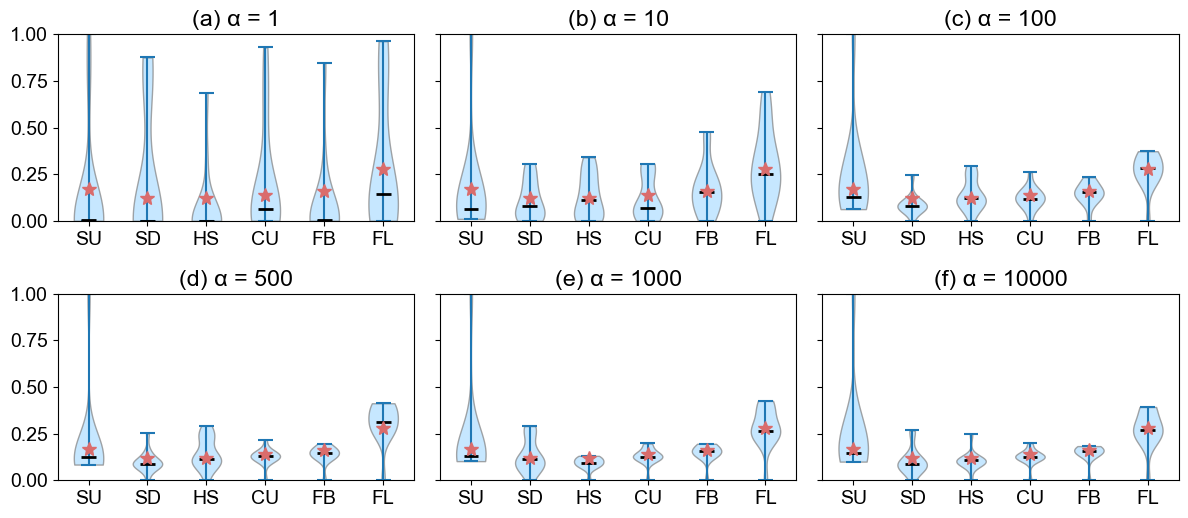

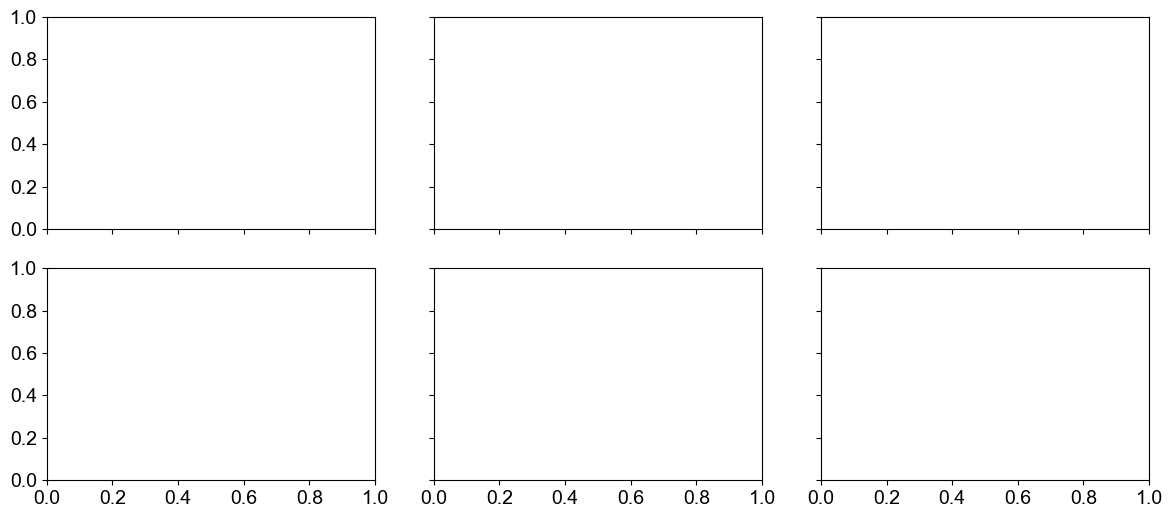

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm

plt.rc('font', family='Arial', size=14)

# --- Base Transition Matrix P (empirical) ---
base_transitions = {
    "follow_behind": {"follow_behind": 0.3902, "catch_up": 0.1313, "fall_behind": 0.1560, "speed_up": 0.1207, "slow_down": 0.0899, "hold_speed": 0.1119},
    "catch_up": {"slow_down": 0.2578, "fall_behind": 0.1383, "hold_speed": 0.1060, "speed_up": 0.1152, "follow_behind": 0.2572, "catch_up": 0.1255},
    "slow_down": {"follow_behind": 0.2148, "fall_behind": 0.1785, "hold_speed": 0.0970, "slow_down": 0.0704, "speed_up": 0.3119, "catch_up": 0.1274},
    "fall_behind": {"follow_behind": 0.2945, "hold_speed": 0.1137, "speed_up": 0.2623, "catch_up": 0.1170, "slow_down": 0.0644, "fall_behind": 0.1481},
    "speed_up": {"fall_behind": 0.1861, "speed_up": 0.1481, "follow_behind": 0.2622, "slow_down": 0.1324, "catch_up": 0.1927, "hold_speed": 0.0786},
    "hold_speed": {"slow_down": 0.0884, "follow_behind": 0.2911, "fall_behind": 0.1337, "hold_speed": 0.2514, "catch_up": 0.1337, "speed_up": 0.1017}
}
all_patterns = ["speed_up", "slow_down", "hold_speed", "catch_up", "fall_behind", "follow_behind"]

def make_base_matrix(trans_dict, patterns):
    P = np.zeros((len(patterns), len(patterns)))
    for i, pi in enumerate(patterns):
        for j, pj in enumerate(patterns):
            P[i, j] = trans_dict[pi][pj]
    return P

P_base = make_base_matrix(base_transitions, all_patterns)

abbr = {
    "speed_up":      "SU",
    "slow_down":     "SD",
    "hold_speed":    "HS",
    "follow_behind": "FL",
    "catch_up":      "CU",
    "fall_behind":   "FB"
}

def generate_driver_phases(num_vehicles, total_time, lambd, mu_dur, sigma_dur, min_dur=0.5):
    driver_phases, driver_probs = {}, {}
    for m in range(num_vehicles):
        patterns = ["follow_behind"]
        first_dur = max(np.random.normal(mu_dur, sigma_dur), min_dur)
        durations = [first_dur]
        probs = [np.eye(len(all_patterns))[0]]
        t_acc, prev = first_dur, "follow_behind"
        while t_acc < total_time:
            P_m = np.array([np.random.dirichlet(lambd * P_base[i])
                            for i in range(len(all_patterns))])
            idx = all_patterns.index(prev)
            row = P_m[idx].copy()
            nxt = np.random.choice(all_patterns, p=row)
            dur = max(np.random.normal(mu_dur, sigma_dur), min_dur)
            patterns.append(nxt)
            durations.append(dur)
            probs.append(row)
            t_acc += dur
            prev = nxt
        driver_phases[m] = {'patterns': patterns, 'durations': durations}
        driver_probs[m] = np.vstack(probs)
    return driver_phases, driver_probs


# --- Metric Calculation ---
def calculate_average_ttc(traffic_data, num_vehicles, vehicle_length=5.0, delta_t=0.1):
    ttc_values, tet_values = [], []
    total_vsp, tet_count = 0, 0
    for vid in range(1, num_vehicles):
        veh = traffic_data[traffic_data['vehicle_id']==vid]
        lead = traffic_data[traffic_data['vehicle_id']==vid-1]
        for t in veh['time'].unique():
            vrow = veh[veh['time']==t].iloc[0]
            lrow = lead[lead['time']==t]
            if lrow.empty: continue
            lrow = lrow.iloc[0]
            x_i, v_i, a_i = vrow['position'], vrow['velocity'], vrow['acceleration']
            x_l, v_l = lrow['position'], lrow['velocity']
            vsp = 0.132*v_i + 1.1*v_i*a_i + 0.0003202*v_i**3
            total_vsp += vsp*delta_t
            dv = v_i - v_l
            if dv < 0:
                ttc = (x_l - x_i - vehicle_length)/abs(dv)
                ttc_values.append(ttc)
                if 0<=ttc<=2:
                    tet_values.append(ttc); tet_count+=1
    return total_vsp, (np.mean(ttc_values) if ttc_values else np.inf), (np.mean(tet_values) if tet_values else np.inf), tet_count

def simulate_traffic_flow(cfg):
    """
    Run the traffic simulation using pre-generated driver phases.
    Expects cfg to contain:
      - num_vehicles, initial_positions, initial_velocities,
      - total_time, vehicle_length, delta_t,
      - lambda_concentration, mu_dur, sigma_dur,
      - min_duration, transition_time
    """
    N = cfg['num_vehicles']
    pos0 = cfg['initial_positions']
    vel0 = cfg['initial_velocities']
    T   = cfg['total_time']
    L   = cfg['vehicle_length']
    dt  = cfg['delta_t']

    lambd     = cfg['lambda_concentration']
    mu_dur    = cfg['mu_dur']
    sigma_dur = cfg['sigma_dur']
    min_dur   = cfg['min_duration']
    trans_t   = cfg['transition_time']
    K = max(int(np.ceil(trans_t / dt)), 1)

    # Generate phases with the correct mu/sigma
    phases, probs_dict = generate_driver_phases(
        N, T, lambd, mu_dur, sigma_dur, min_dur
    )

    # Initialize vehicles
    vehicles = [{
        'id': i,
        'pos': pos0[i],
        'vel': vel0[i],
        'acc': 0.0,
        'last_pattern': all_patterns[0],
        'trans_steps': 0,
        'a_prev': 0.0,
        'a_target': 0.0
    } for i in range(N)]

    records   = []
    collisions = 0
    t = 0.0

    def get_pattern(m, t_cur):
        cum = np.cumsum(phases[m]['durations'])
        idx = np.searchsorted(cum, t_cur)
        return phases[m]['patterns'][min(idx, len(cum)-1)]

    # Main time loop
    while t < T:
        prev_pos = [v['pos'] for v in vehicles]
        prev_vel = [v['vel'] for v in vehicles]
        for i, v in enumerate(vehicles):
            pat = get_pattern(i, t)
            if i == 0:
                a_new = 0.0
                v_new = max(v['vel'], 5)
                x_new = v['pos'] + v_new * dt
            else:
                s  = max(prev_pos[i-1] - prev_pos[i] - L, 0.1)
                dv = prev_vel[i-1] - prev_vel[i]
                if pat in ['speed_up', 'slow_down']:
                    raw   = (2.28/np.sqrt(s) - 0.19)*dv + np.random.normal(0, 0.1)
                    a_new = np.clip(-3.4 * raw, -3, 3)
                elif pat == 'hold_speed':
                    a_new = np.random.normal(0, 0.1)
                elif pat == 'catch_up':
                    Kc, ac, st = -0.0266, 1.06, 20
                    a_new = np.clip(Kc*(st - s) + ac*dv, -3, 3)
                elif pat == 'fall_behind':
                    Kf, af, st = 0.0093, 0.9144, 30
                    a_new = np.clip(Kf*(st - s) + af*dv, -3, 3)
                else:  # follow_behind
                    Kfb, afb, sd = -0.0045, 0.927, 40
                    a_new = np.clip(Kfb*(sd - s) + afb*dv, -3, 3)

                v_new = max(v['vel'] + a_new * dt, 0)
                x_new = prev_pos[i] + v_new * dt
                if x_new >= prev_pos[i-1]:
                    collisions += 1

            # Smooth transitions
            if pat != v['last_pattern']:
                v['trans_steps'] = K
                v['a_prev']     = v['acc']
                v['a_target']   = a_new
            if v['trans_steps'] > 0:
                k = K - v['trans_steps']
                a = (1 - k/K)*v['a_prev'] + (k/K)*v['a_target']
                v['trans_steps'] -= 1
            else:
                a = a_new

            records.append({
                'vehicle_id':  i,
                'time':        round(t,4),
                'pattern':     pat,
                'acceleration':a,
                'velocity':    v_new,
                'position':    x_new
            })
            v.update({'pos': x_new, 'vel': v_new, 'acc': a, 'last_pattern': pat})

        t += dt

    return pd.DataFrame(records), phases, probs_dict, collisions

# --- Violin Plot of pattern-transition probabilities ---
def plot_pattern_violin(probs, patterns, output_filename=None):
    data = [probs[:, i] for i in range(len(patterns))]
    labels = [p.replace('_', ' ').title() for p in patterns]
    fig, ax = plt.subplots(figsize=(5, 4))
    parts = ax.violinplot(data, showmeans=False, showmedians=True)
    for pc in parts['bodies']:
        pc.set_facecolor('#8FB9A8'); pc.set_edgecolor('black'); pc.set_alpha(0.7)
    parts['cmedians'].set_edgecolor('black'); parts['cmedians'].set_linewidth(2)
    ax.yaxis.grid(True, linestyle='--', alpha=0.6)
    ax.set_xticks(np.arange(1, len(labels) + 1)); ax.set_xticklabels(labels, rotation=45)
    ax.set_ylabel('Tran. Prob.'); 
    ax.set_title('Pattern Transition Probabilities')
    ax.set_xlabel('Action Pattern')
    plt.tight_layout()
    if output_filename:
        plt.savefig(output_filename, dpi=300, bbox_inches='tight')
        print(f"Saved violin to {output_filename}")
    plt.show()

# --- Trajectory Visualization ---
def plot_simulation_results(traffic_data, num_vehicles, dt, output_filename=None):
    colors = cm.get_cmap('tab20c', num_vehicles)
    fig, axes = plt.subplots(3, 1, figsize=(8, 9), sharex=True)
    for i in range(1, num_vehicles):
        d_i = traffic_data[traffic_data['vehicle_id'] == i]
        axes[0].plot(d_i['time'], d_i['position'], color=colors(i))
        axes[1].plot(d_i['time'], d_i['velocity'], color=colors(i))
        axes[2].plot(d_i['time'], d_i['acceleration'], color=colors(i))
    axes[0].set_ylabel('Location (m)'); axes[0].set_title('(a) Vehicle Location')
    axes[1].set_ylabel('Velocity (m/s)'); axes[1].set_title('(b) Vehicle Velocity')
    axes[2].set_ylabel('Acceleration (m/s²)'); axes[2].set_title('(c) Vehicle Acceleration')
    axes[2].set_xlabel('Time (s)')
    plt.tight_layout()
    if output_filename:
        plt.savefig(output_filename, dpi=300, bbox_inches='tight')
        print(f"Saved figure to {output_filename}")
    plt.show()

if __name__ == "__main__":
    lambdas = [1, 10, 100, 500, 1000, 10000]
    base_cfg = {
        'num_vehicles':     20,
        'initial_positions': np.linspace(0, -1000, 20),
        'initial_velocities': np.full(20, 15),
        'total_time':       60,
        'vehicle_length':   5.0,
        'delta_t':          0.1,
        'mu_dur':           4.0,
        'sigma_dur':        0.0,
        'min_duration':     0.5,
        'transition_time':  1.0
    }

    letters = ['(a)', '(b)', '(c)', '(d)', '(e)', '(f)']

    fig_vio, axes_vio = plt.subplots(2, 3, figsize=(12, 6), sharey=True)
    fig_vel, axes_vel = plt.subplots(2, 3, figsize=(12, 6), sharex=True, sharey=True)

for idx, (ax_vio, ax_vel, lam) in enumerate(zip(axes_vio.flat, axes_vel.flat, lambdas)):
    label = letters[idx]

    # 1) violin plot of driver 5
    _, driver_probs = generate_driver_phases(
        base_cfg['num_vehicles'],
        base_cfg['total_time'],
        lam,
        base_cfg['mu_dur'],
        base_cfg['sigma_dur'],
        base_cfg['min_duration']
    )
    data = [driver_probs[5][:, i] for i in range(len(all_patterns))]
    vp = ax_vio.violinplot(data, showmedians=True)

    for pc in vp['bodies']:
        pc.set_facecolor('#AFDDFF')
        pc.set_edgecolor('gray')
        pc.set_alpha(0.7)
    vp['cmedians'].set_edgecolor('black')
    vp['cmedians'].set_linewidth(2)

    ax_vio.set_xticks(np.arange(1, len(all_patterns) + 1))
    ax_vio.set_xticklabels([abbr[p] for p in all_patterns], rotation=0)
    ax_vio.set_title(f"{label} α = {lam}")
    ax_vio.set_ylim(0, 1)

    # ★ Add reference-value stars only (no text)
    reference_values = [0.17, 0.12, 0.12, 0.14, 0.16, 0.28]  # SU, SD, HS, CU, FB, FL
    for i, val in enumerate(reference_values):
        ax_vio.plot(
            i + 1,      # x-position
            val,        # y-value
            marker='*',
            markersize=10,
            linestyle='none',
            color='#DA6C6C'
        )

# tidy and show
# fig_vio.suptitle("Driver 5 Pattern Transition Violin Plots", y=0.92)

fig_vio.tight_layout(rect=[0,0,1,0.90])
fig_vio.savefig("alpha_comparison_driver5_mark.pdf", dpi=300)

fig_vel.tight_layout(rect=[0,0,1,0.90])

plt.show()

# Beta variability

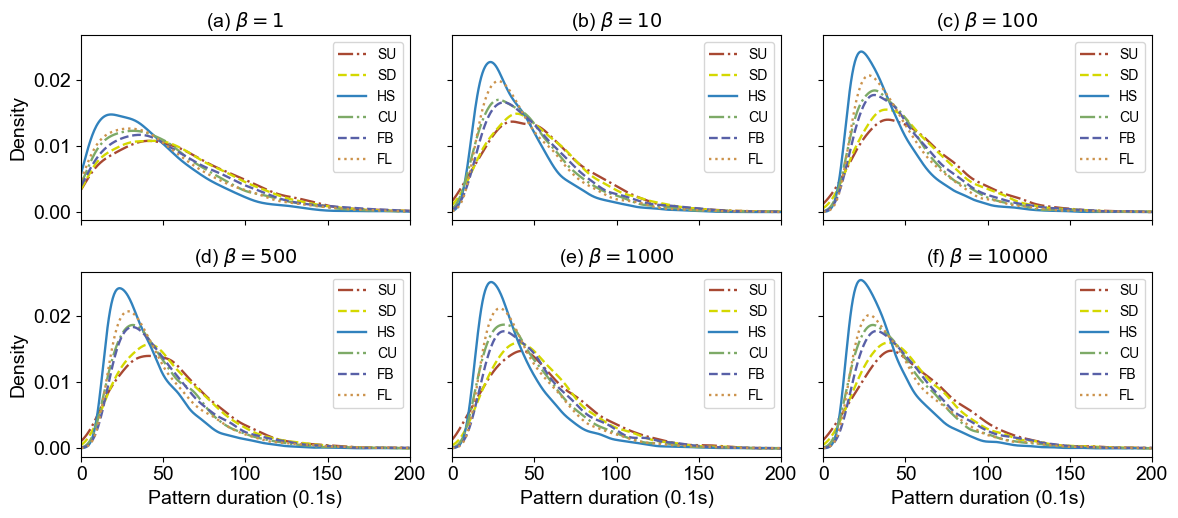

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde, pearson3

plt.rc('font', family='Arial', size=14)
raw_params = {
    "CU": [47.841042, 714.930387, 1.382377, 2.465581],
    "FB": [51.427919, 824.589774, 1.427946, 2.731621],
    "FL": [47.197166, 724.236071, 1.588814, 3.821576],
    "SU": [54.357868, 921.487722, 0.899142, 0.934809], 
    "SD": [53.776271, 840.973094, 1.083641, 1.866133], 
    "HS": [40.124668, 530.546658, 1.670533, 4.203144]
}

betas = [1, 10, 100, 500, 1000, 10000]
patterns = [
    ("SU", '-.'),
    ("SD", '--'),
    ("HS", '-'),
    ("CU", '-.'),
    ("FB", '--'),
    ("FL", ':')
]


global_pattern_colors = {
    "SU": "#A84832",
    "SD": "#D4D800",
    "HS": "#3182BD",
    "CU": "#7DAA67",
    "FB": "#5860A7",
    "FL": "#CC934C"
}

x = np.linspace(0, 200, 500)
letters = list("abcdef")

fig, axes = plt.subplots(2, 3, figsize=(12, 6), sharex=True, sharey=True)

for idx, (ax, β) in enumerate(zip(axes.flatten(), betas)):
    for pat, ls in patterns:
        μ, var, skew, _ = raw_params[pat]
        σ = np.sqrt(var)
        # adjust for β
        σ_eff    = σ * np.sqrt(1 + 1/β)
        skew_eff = skew * np.sqrt(β / (β + 1))
        dist = pearson3(skew=skew_eff, loc=μ, scale=σ_eff)
        samples = dist.rvs(size=5000)
        samples = samples[samples > 0]
        kde = gaussian_kde(samples)

        ax.plot(
            x, kde(x),
            color=global_pattern_colors[pat],
            linestyle=ls,
            linewidth=1.7,
            label=pat
        )

    # per‐subplot legend
    ax.legend(
        fontsize=10,
        title_fontsize=14,
        loc="upper right",
        frameon=True,
    )

    letter = letters[idx]
    ax.set_title(f"({letter}) $\\beta={β}$", fontsize=14)
    ax.set_xlim(0, 200)
    if ax.is_first_col():
        ax.set_ylabel("Density")
    if ax.is_last_row():
        ax.set_xlabel("Pattern duration (0.1s)")

plt.tight_layout(rect=[0,0,1,0.90])
plt.savefig(
    "duration_kde_driver5_exp.pdf",
    dpi=300, bbox_inches='tight'
)
plt.show()


In [695]:
import numpy as np
import pandas as pd
from scipy.stats import pearson3

raw_params = {
    "CU": [47.841042, 714.930387, 1.382377, 2.465581],
    "FB": [51.427919, 824.589774, 1.427946, 2.731621],
    "FL": [47.197166, 724.236071, 1.588814, 3.821576],
    "SU": [54.357868, 921.487722, 0.899142, 0.934809],
    "SD": [53.776271, 840.973094, 1.083641, 1.866133],
    "HS": [40.124668, 530.546658, 1.670533, 4.203144]
}

betas = [1, 10, 100, 500, 1000, 10000]
patterns = ["SU","SD","HS","CU","FB","FL"]

for β in betas:
    rows = []
    for pat in patterns:
        μ, var, skew, _ = raw_params[pat]
        σ = np.sqrt(var)
        σ_eff    = σ * np.sqrt(1 + 1/β)
        skew_eff = skew * np.sqrt(β / (β + 1))
        rows.append({
            "pattern": pat,
            "μ (orig)": μ,
            "σ_eff":    σ_eff,
            "skew_eff": skew_eff
        })
    df = pd.DataFrame(rows).set_index("pattern")
    print(f"\nAdjusted parameters for β = {β}:\n")
    print(df.round(4))



Adjusted parameters for β = 1:

         μ (orig)    σ_eff  skew_eff
pattern                             
SU        54.3579  42.9299    0.6358
SD        53.7763  41.0115    0.7662
HS        40.1247  32.5744    1.1812
CU        47.8410  37.8135    0.9775
FB        51.4279  40.6101    1.0097
FL        47.1972  38.0588    1.1235

Adjusted parameters for β = 10:

         μ (orig)    σ_eff  skew_eff
pattern                             
SU        54.3579  31.8377    0.8573
SD        53.7763  30.4150    1.0332
HS        40.1247  24.1578    1.5928
CU        47.8410  28.0432    1.3180
FB        51.4279  30.1173    1.3615
FL        47.1972  28.2252    1.5149

Adjusted parameters for β = 100:

         μ (orig)    σ_eff  skew_eff
pattern                             
SU        54.3579  30.5074    0.8947
SD        53.7763  29.1442    1.0783
HS        40.1247  23.1485    1.6622
CU        47.8410  26.8715    1.3755
FB        51.4279  28.8589    1.4209
FL        47.1972  27.0459    1.5809

Adjusted 

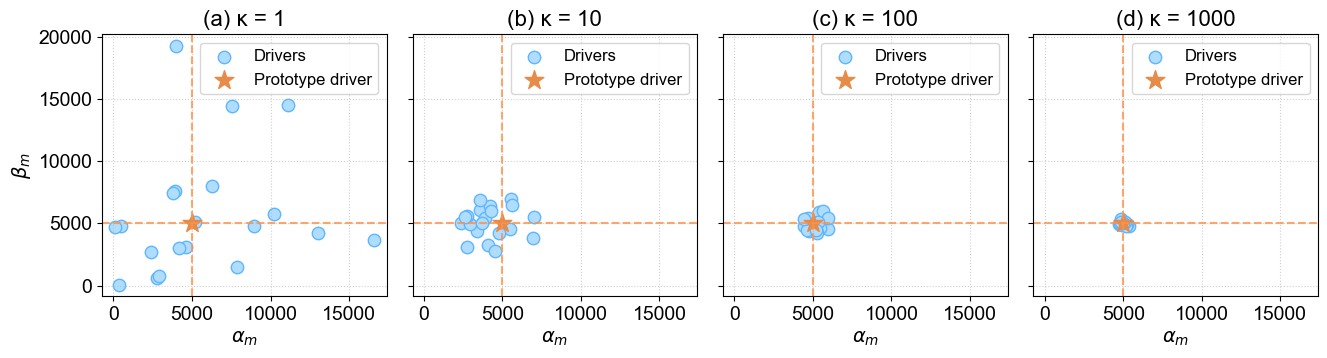

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

plt.rc('font', family='Arial', size=14)
# reproducibility
np.random.seed(0)

# prototype mean
theta = 5000  

# number of drivers
num_drivers = 20

# the three κ values and subplot labels
kappas = [1, 10, 100, 1000]
labels = ['(a) κ = 1', '(b) κ = 10', '(c) κ = 100', '(d) κ = 1000']

# prepare figure
fig, axes = plt.subplots(1, 4, figsize=(13.5, 3.8), sharex=True, sharey=True)

for ax, κ, lbl in zip(axes, kappas, labels):
    # independently sample alpha_m and beta_m from Gamma(κ, θ/κ)
    alpha_m = np.random.gamma(shape=κ, scale=theta/κ, size=num_drivers)
    beta_m  = np.random.gamma(shape=κ, scale=theta/κ, size=num_drivers)

    # scatter the driver‐specific points
    ax.scatter(alpha_m, beta_m, c='#AFDDFF', edgecolor='#60B5FF', s=80, label='Drivers')

    # guide lines at prototype
    ax.axvline(theta, color='#FF9149', linestyle='--', alpha=0.8)
    ax.axhline(theta, color='#FF9149', linestyle='--', alpha=0.8)

    # plot the prototype point
    ax.scatter([theta], [theta], c='#E78B48', marker='*', s=200, label='Prototype driver')

    ax.set_title(lbl, fontsize=16)
    ax.set_xlabel(r'$\alpha_m$', fontsize=14)
    if ax is axes[0]:
        ax.set_ylabel(r'$\beta_m$', fontsize=14)
    ax.legend(loc='upper right', fontsize=12, title_fontsize=12, frameon=True)
    ax.grid(linestyle=':', alpha=0.6)

plt.tight_layout()
plt.savefig(
    "gama_example.pdf",
    dpi=300, bbox_inches='tight'
)
plt.show()


# Disturbance impacts

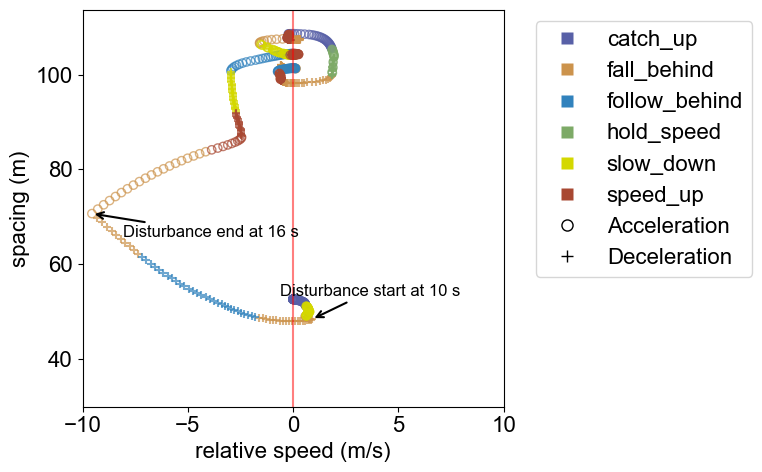

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# === 1) Load your CSV files ===
ts_filename     = "simulation_timeseries_lambda_10000.csv"
pattern_name_fn = "pattern_name_simulation_lambda_10000.csv"

df_ts           = pd.read_csv(ts_filename)
df_pattern_name = pd.read_csv(pattern_name_fn)

# === 2) Preprocess and build (vehicle_id, phase_idx) → pattern lookup ===
df_ts.sort_values(by=['vehicle_id', 'time'], inplace=True)
pattern_lookup = {
    (int(row.vehicle_id), int(row.phase_idx)): row.pattern
    for _, row in df_pattern_name.iterrows()
}

# === 3) Select leader and follower ===
lead_id = 4
foll_id = 5

df_lead = df_ts[df_ts['vehicle_id'] == lead_id].set_index('time')
df_foll = df_ts[df_ts['vehicle_id'] == foll_id].set_index('time')

common_times = df_lead.index.intersection(df_foll.index)
if len(common_times) < 2:
    raise RuntimeError(f"Not enough overlapping time points for vehicles {lead_id} and {foll_id}.")

# === 4) Extract position & velocity, compute spacing & relative speed ===
t_common = np.array(common_times)
x_lead   = df_lead.loc[common_times, 'position'].values
v_lead   = df_lead.loc[common_times, 'velocity'].values
x_foll   = df_foll.loc[common_times, 'position'].values
v_foll   = df_foll.loc[common_times, 'velocity'].values

spacing   = x_lead - x_foll
rel_speed = v_foll - v_lead  # positive when follower faster than leader

# Compute follower’s acceleration for marker selection
acc_foll = np.gradient(v_foll, t_common)

# === 5) Assign follower’s pattern label at each time ===
phase_duration = 3.0
pattern_labels = []
for t in t_common:
    phase_idx = int(np.floor(t / phase_duration))
    pat = pattern_lookup.get((foll_id, phase_idx), "unknown")
    pattern_labels.append(pat)
pattern_labels = np.array(pattern_labels)

unique_patterns = sorted(df_pattern_name['pattern'].unique())

# === 6) Define explicit colors for the six patterns ===
color_map = {
    "speed_up":     "#A84832",  # brown‐red
    "slow_down":    "#D4D800",  # yellow
    "hold_speed":   "#7DAA67",  # green
    "catch_up":     "#5860A7",  # blue
    "fall_behind":  "#CC934C",  # orange
    "follow_behind":"#3182BD",  # sky‐blue
    "unknown":      "#7f7f7f"   # gray fallback
}

# === 7) Locate indices closest to t = 10 s (start) and t = 16 s (end) ===
idx_start = np.argmin(np.abs(t_common - 10.0))
idx_end   = np.argmin(np.abs(t_common - 16.0))

# === 8) Plot Δv vs. Spacing, colored by pattern, using 'o' for accel and '+' for decel ===
plt.figure(figsize=(8, 5))

for pat in unique_patterns:
    # deceleration points (“+”)
    idx_decel = np.where((pattern_labels == pat) & (acc_foll < 0))[0]
    plt.scatter(
        rel_speed[idx_decel],
        spacing[idx_decel],
        marker='+',
        color=color_map.get(pat, "#7f7f7f"),
        alpha=0.7
    )
    # acceleration points (“o”)
    idx_accel = np.where((pattern_labels == pat) & (acc_foll > 0))[0]
    plt.scatter(
        rel_speed[idx_accel],
        spacing[idx_accel],
        marker='o',
        facecolors='none',
        edgecolors=color_map.get(pat, "#7f7f7f"),
        alpha=0.7
    )

# === 9) Mark t=10s (start) and t=16s (end) with arrows ===
plt.annotate(
    "Disturbance start at 10 s",
    xy=(rel_speed[idx_start], spacing[idx_start]),
    xytext=(rel_speed[idx_start] - 1.5, spacing[idx_start] + 5),
    arrowprops=dict(arrowstyle="->", color='black', lw=1.5),
    fontsize=12
)
plt.annotate(
    "Disturbance end at 16 s",
    xy=(rel_speed[idx_end], spacing[idx_end]),
    xytext=(rel_speed[idx_end] + 1.5, spacing[idx_end] - 5),
    arrowprops=dict(arrowstyle="->", color='black', lw=1.5),
    fontsize=12
)

# === 10) Optional vertical reference line at Δv = 0 ===
plt.axvline(x=0, color='red', linewidth=1.5, alpha=0.5)

# === 11) Final formatting ===
plt.xlabel("relative speed (m/s)")
plt.ylabel("spacing (m)")
plt.xlim(-10, 10)
plt.ylim(30, max(spacing) + 5)

# === 12) Build custom legend ===
# First, one entry per pattern (hollow circle shows color only)
pattern_handles = [
    Line2D([0], [0],
           marker='s',
           color=color_map.get(pat, "#7f7f7f"),
           linestyle='',
           markeredgecolor='none',
           markerfacecolor=color_map.get(pat, "#7f7f7f"),
           markersize=8,
           label=pat
    )
    for pat in unique_patterns
]
# Next, shape legend entries for accel vs decel
shape_handles = [
    Line2D([0], [0], marker='o', color='black', linestyle='', markerfacecolor='none', markersize=8, label='Acceleration'),
    Line2D([0], [0], marker='+', color='black', linestyle='', markersize=8, label='Deceleration')
]

# Combine handles: patterns first, then shapes
all_handles = pattern_handles + shape_handles
plt.legend(handles=all_handles, bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()


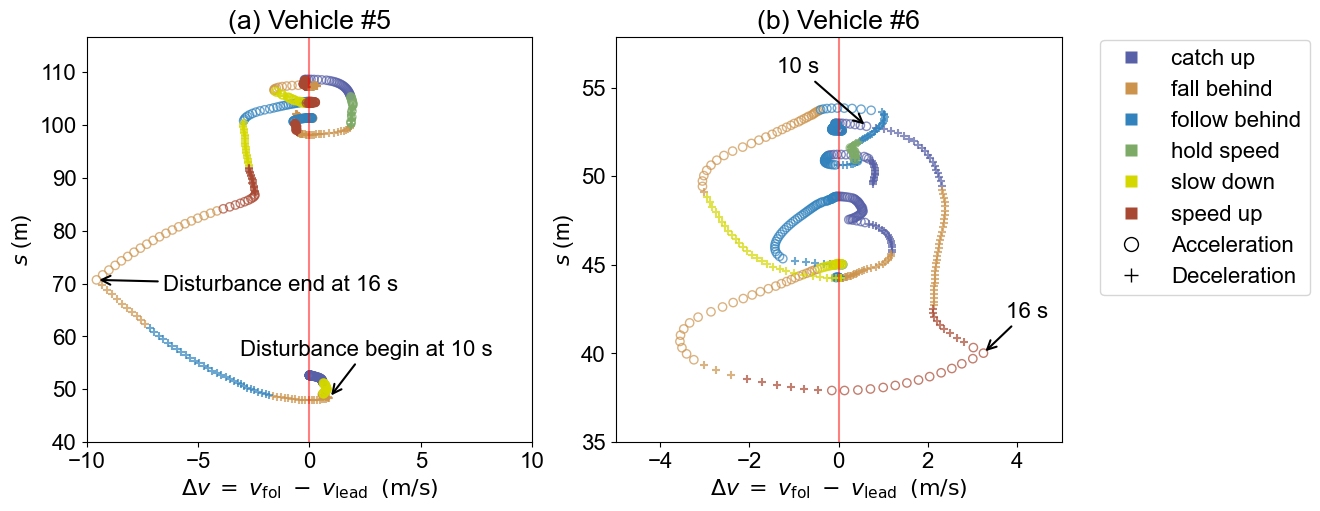

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# === 1) File paths (update if needed) ===
ts_filename     = "simulation_timeseries_lambda_10000.csv"
pattern_name_fn = "pattern_name_simulation_lambda_10000.csv"

df_ts           = pd.read_csv(ts_filename)
df_pattern_name = pd.read_csv(pattern_name_fn)

# === 2) Build (vehicle_id, phase_idx) → pattern lookup ===
df_ts.sort_values(by=['vehicle_id', 'time'], inplace=True)
pattern_lookup = {
    (int(row.vehicle_id), int(row.phase_idx)): row.pattern
    for _, row in df_pattern_name.iterrows()
}

# === 3) Plotting function for one leader–follower pair (scatter only) ===
def plot_dv_vs_spacing_base(ax, lead_id, foll_id, color_map):
    df_lead = df_ts[df_ts['vehicle_id'] == lead_id].set_index('time')
    df_foll = df_ts[df_ts['vehicle_id'] == foll_id].set_index('time')
    common_times = df_lead.index.intersection(df_foll.index)
    if len(common_times) < 2:
        raise RuntimeError(f"No overlapping times for vehicles {lead_id} and {foll_id}.")

    t_common = np.array(common_times)
    x_lead   = df_lead.loc[common_times, 'position'].values
    v_lead   = df_lead.loc[common_times, 'velocity'].values
    x_foll   = df_foll.loc[common_times, 'position'].values
    v_foll   = df_foll.loc[common_times, 'velocity'].values

    spacing   = x_lead - x_foll
    rel_speed = v_foll - v_lead
    acc_foll  = np.gradient(v_foll, t_common)

    # Assign pattern label per time (phase_idx = floor(t/3.0))
    phase_duration = 3.0
    pattern_labels = []
    for t in t_common:
        phase_idx = int(np.floor(t / phase_duration))
        pat = pattern_lookup.get((foll_id, phase_idx), "unknown")
        pattern_labels.append(pat)
    pattern_labels = np.array(pattern_labels)

    unique_patterns = sorted(df_pattern_name['pattern'].unique())

    # Plot each pattern with '+' for decel, 'o' for accel
    for pat in unique_patterns:
        col = color_map.get(pat, "#7f7f7f")
        idx_decel = np.where((pattern_labels == pat) & (acc_foll < 0))[0]
        ax.scatter(rel_speed[idx_decel], spacing[idx_decel],
                   marker='+', color=col, alpha=0.7)
        idx_accel = np.where((pattern_labels == pat) & (acc_foll > 0))[0]
        ax.scatter(rel_speed[idx_accel], spacing[idx_accel],
                   marker='o', facecolors='none', edgecolors=col, alpha=0.7)

    # Return arrays needed for annotation and custom limits
    return t_common, rel_speed, spacing

# === 4) Define pattern color map ===
color_map = {
    "speed_up":     "#A84832",
    "slow_down":    "#D4D800",
    "hold_speed":   "#7DAA67",
    "catch_up":     "#5860A7",
    "fall_behind":  "#CC934C",
    "follow_behind":"#3182BD",
    "unknown":      "#7f7f7f"
}

# === 5) Create figure with two subplots (independent axes) ===
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(13, 4.5))

# Left subplot: vehicles 4 → 5
t1, rel1, sp1 = plot_dv_vs_spacing_base(ax1, lead_id=4, foll_id=5, color_map=color_map)
# Annotate and set limits for left subplot
idx_start1 = np.argmin(np.abs(t1 - 10.0))
idx_end1   = np.argmin(np.abs(t1 - 16.0))
ax1.annotate("Disturbance begin at 10 s",
             xy=(rel1[idx_start1], sp1[idx_start1]),
             xytext=(rel1[idx_start1] - 4, sp1[idx_start1] + 8),
             arrowprops=dict(arrowstyle="->", color='black', lw=1.5),
             fontsize=16)
ax1.annotate("Disturbance end at 16 s",
             xy=(rel1[idx_end1], sp1[idx_end1]),
             xytext=(rel1[idx_end1] + 3, sp1[idx_end1] - 2),
             arrowprops=dict(arrowstyle="->", color='black', lw=1.5),
             fontsize=16)
ax1.set_xlim(-10, 10)
ax1.set_ylim(40, max(sp1) + 8)
ax1.set_xlabel(r"$\Delta v \;=\; v_{\mathrm{fol}} \;-\; v_{\mathrm{lead}}\;\;(\mathrm{m/s})$")
ax1.set_ylabel("$s$ (m)")
ax1.set_title("(a) Vehicle #5")
ax1.axvline(x=0, color='red', linewidth=1.5, alpha=0.5)
# ax1.grid(True, linestyle='--', alpha=0.3)

# Right subplot: vehicles 14 → 15
t2, rel2, sp2 = plot_dv_vs_spacing_base(ax2, lead_id=5, foll_id=6, color_map=color_map)
# Annotate and set limits for right subplot (different from left)
idx_start2 = np.argmin(np.abs(t2 - 10.0))
idx_end2   = np.argmin(np.abs(t2 - 16.0))
ax2.annotate("10 s",
             xy=(rel2[idx_start2], sp2[idx_start2]),
             xytext=(rel2[idx_start2] - 2, sp2[idx_start2] + 3),
             arrowprops=dict(arrowstyle="->", color='black', lw=1.5),
             fontsize=16)
ax2.annotate("16 s",
             xy=(rel2[idx_end2], sp2[idx_end2]),
             xytext=(rel2[idx_end2] + 0.5, sp2[idx_end2] + 2),
             arrowprops=dict(arrowstyle="->", color='black', lw=1.5),
             fontsize=16)
ax2.set_xlim(-5, 5)
ax2.set_ylim(35, max(sp2) + 4)
ax2.set_xlabel(r"$\Delta v \;=\; v_{\mathrm{fol}} \;-\; v_{\mathrm{lead}}\;\;(\mathrm{m/s})$")
ax2.set_ylabel("$s$ (m)")
ax2.set_title("(b) Vehicle #6")
ax2.axvline(x=0, color='red', linewidth=1.5, alpha=0.5)
# ax2.grid(True, linestyle='--', alpha=0.3)

# === 6) Build a shared legend ===
pattern_handles = [
    Line2D([0], [0], marker='s', color=color_map[pat], linestyle='',
           markeredgecolor='none', markerfacecolor=color_map[pat], markersize=8,
           label=pat.replace('_', ' '))
    for pat in sorted(df_pattern_name['pattern'].unique())
]
shape_handles = [
    Line2D([0], [0], marker='o', color='black', linestyle='',
           markerfacecolor='none', markersize=10, label='Acceleration'),
    Line2D([0], [0], marker='+', color='black', linestyle='', markersize=10,
           label='Deceleration')
]
all_handles = pattern_handles + shape_handles


# Place the legend to the right of the subplots
fig.legend(
    handles=all_handles,
    loc='center right',
    fontsize='medium',
    bbox_to_anchor=(1.00, 0.66),
    frameon=True
)

plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.subplots_adjust(left=0.05, right=0.8, top=0.95, bottom=0.05)
plt.savefig("dv_vs_spacing_leader_follower.pdf", bbox_inches='tight')
plt.show()


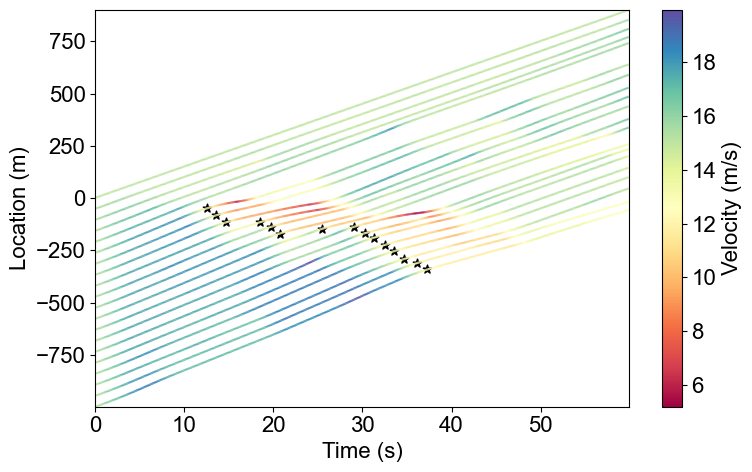

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection

plt.rc('font', family='Arial', size=16)
# === 1) Load time‐series data ===
# Update this path to match your local setup:
ts_filename = "simulation_timeseries_lambda_10000.csv"
df = pd.read_csv(ts_filename)

# Sort by vehicle_id and time for consistency
df.sort_values(by=['vehicle_id', 'time'], inplace=True)

# === 2) Define disturbance window (for reference) ===
disturbance_start = 10  # seconds
disturbance_end   = 16  # seconds

# === 3) Identify “disturbed” vehicle onward ===
# We assume “disturbed vehicle” has ID = 5, and we want vehicles 5 through the last.
start_vid = 5
vehicle_ids = df['vehicle_id'].unique()
# Filter to all IDs ≥ 5 (5, 6, 7, …)
affected_ids = [vid for vid in vehicle_ids if vid >= start_vid]

# === 4) For each affected vehicle, find the first time when speed < 10 m/s ===
threshold_speed = 13.0  # m/s
first_slow_points = []
for vid in affected_ids:
    df_vid = df[df['vehicle_id'] == vid]
    # Find the first row where velocity < threshold_speed
    below_thresh = df_vid[df_vid['velocity'] < threshold_speed]
    if below_thresh.empty:
        continue
    row_first = below_thresh.iloc[0]
    t_first = row_first['time']
    x_first = row_first['position']
    first_slow_points.append((vid, t_first, x_first))

# === 5) Plot all trajectories colored by velocity ===
fig, ax = plt.subplots(figsize=(8, 5))
cmap = plt.get_cmap('Spectral')
norm = plt.Normalize(df['velocity'].min(), df['velocity'].max())

for vid in vehicle_ids:
    df_vid = df[df['vehicle_id'] == vid]
    t = df_vid['time'].values
    x = df_vid['position'].values
    v = df_vid['velocity'].values
    
    # Build line segments to color by velocity
    points = np.array([t, x]).T.reshape(-1, 1, 2)
    segments = np.concatenate([points[:-1], points[1:]], axis=1)
    v_avg = (v[:-1] + v[1:]) / 2.0
    
    lc = LineCollection(segments, cmap=cmap, norm=norm, linewidth=1.5)
    lc.set_array(v_avg)
    ax.add_collection(lc)

# Add colorbar for velocity
cbar = plt.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=ax)
cbar.set_label('Velocity (m/s)')

# === 6) Draw slowdown‐window reference lines ===
# ax.axvline(disturbance_start, color='orange', linestyle='--', linewidth=1.5, label='Disturbance Start (10 s)')
# ax.axvline(disturbance_end, color='purple', linestyle='--', linewidth=1.5, label='Disturbance End (16 s)')

# === 7) Overlay first‐slow (v < 10 m/s) points for vehicles ≥ 5 ===
# Use a distinct marker (black star) for each point; no labels so they do not appear in legend
for (vid, t_first, x_first) in first_slow_points:
    ax.scatter(t_first, x_first, marker='*', color='black', s=40)

# === 8) Final plot formatting ===
ax.set_xlabel("Time (s)")
ax.set_ylabel("Location (m)")
# ax.set_title("Trajectories Colored by Velocity\nFirst Time (v < 10 m/s) for Vehicles ≥ 5")
ax.set_xlim(df['time'].min(), df['time'].max())
ax.set_ylim(df['position'].min(), df['position'].max())

# Only show legend entries for the slowdown lines
# ax.legend(loc='upper left', fontsize=14)

plt.tight_layout()
plt.savefig("traffic_trajectories_with_slowdown(1).pdf", dpi=300, bbox_inches='tight')
plt.show()


In [ ]:
import pandas as pd
import numpy as np

# === 1) Load your time‐series CSV ===
# Make sure this path matches the actual location of your file
ts_filename = "simulation_timeseries_lambda_10000.csv"
df = pd.read_csv(ts_filename)

# Sort by vehicle_id and time for consistency
df.sort_values(by=['vehicle_id', 'time'], inplace=True)

# === 2) Identify “affected” vehicles (ID ≥ 5) ===
start_vid = 5
all_ids = sorted(df['vehicle_id'].unique())
affected_ids = [vid for vid in all_ids if vid >= start_vid]

# === 3) For each affected vehicle, find the FIRST time its speed < 10 m/s ===
threshold_speed = 13.0  # m/s
star_points = []        # Will hold tuples (vehicle_id, t_star, x_star)

for vid in affected_ids:
    df_vid = df[df['vehicle_id'] == vid]
    df_slow = df_vid[df_vid['velocity'] < threshold_speed]
    if df_slow.empty:
        continue

    # Take the very first row where v < 10 m/s
    row = df_slow.iloc[0]
    t_star = row['time']
    x_star = row['position']
    star_points.append((vid, t_star, x_star))

# Sort by vehicle_id to ensure the same ordering as on the plot
star_points.sort(key=lambda r: r[0])

# === 4) Print star points for debugging ===
print("Star points (vehicle, time, location):")
for vid, t_star, x_star in star_points:
    print(f"  Veh {vid}:  t = {t_star:.2f}  s,  x = {x_star:.2f}  m")

# === 5) Compute slopes between adjacent star points ===
wave_slopes = []
for i in range(len(star_points) - 1):
    vid_i, t_i, x_i = star_points[i]
    vid_j, t_j, x_j = star_points[i + 1]

    dt = t_j - t_i
    dx = x_j - x_i
    if dt == 0:
        slope = np.nan
    else:
        slope = dx / dt

    wave_slopes.append(((vid_i, vid_j), slope))

# === 6) Print the slopes ===
print("\nSlopes of lines connecting adjacent star points:")
for (vid_i, vid_j), s in wave_slopes:
    print(f"  Veh {vid_i} → Veh {vid_j}:  slope = {s:.2f}  m/s")


Star points (vehicle, time, location):
  Veh 5:  t = 12.50  s,  x = -49.50  m
  Veh 6:  t = 13.60  s,  x = -82.04  m
  Veh 7:  t = 14.70  s,  x = -116.06  m
  Veh 8:  t = 18.50  s,  x = -115.58  m
  Veh 9:  t = 19.70  s,  x = -138.10  m
  Veh 10:  t = 20.70  s,  x = -169.75  m
  Veh 11:  t = 25.40  s,  x = -147.97  m
  Veh 12:  t = 29.00  s,  x = -138.36  m
  Veh 13:  t = 30.30  s,  x = -167.94  m
  Veh 14:  t = 31.30  s,  x = -189.48  m
  Veh 15:  t = 32.50  s,  x = -224.45  m
  Veh 16:  t = 33.50  s,  x = -254.84  m
  Veh 17:  t = 34.70  s,  x = -291.42  m
  Veh 18:  t = 36.10  s,  x = -311.45  m
  Veh 19:  t = 37.30  s,  x = -341.57  m

Slopes of lines connecting adjacent star points:
  Veh 5 → Veh 6:  slope = -29.58  m/s
  Veh 6 → Veh 7:  slope = -30.93  m/s
  Veh 7 → Veh 8:  slope = 0.13  m/s
  Veh 8 → Veh 9:  slope = -18.77  m/s
  Veh 9 → Veh 10:  slope = -31.65  m/s
  Veh 10 → Veh 11:  slope = 4.63  m/s
  Veh 11 → Veh 12:  slope = 2.67  m/s
  Veh 12 → Veh 13:  slope = -22.75  m/

Fitted parameters for Platoon 1:  A=2.793, B=0.204
Fitted parameters for Platoon 2:  A=5.679, B=0.053


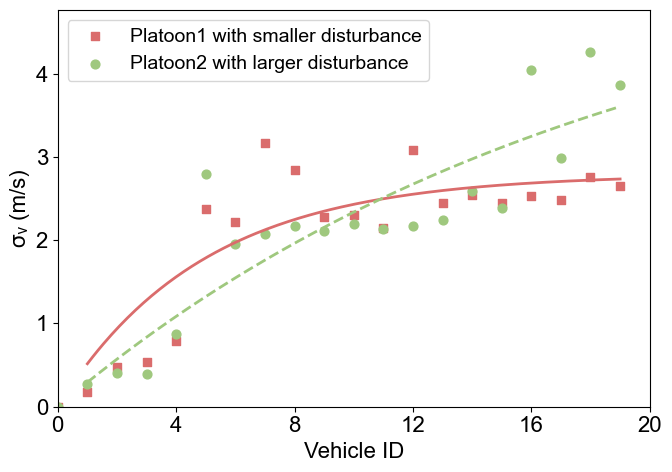

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from matplotlib.ticker import MaxNLocator

# === 1) File paths ===
file1 = "simulation_timeseries_lambda_10000.csv"
file2 = "E2-simulation_timeseries_lambda_10000.csv"

# === 2) Load each dataset ===
df1 = pd.read_csv(file1)
df2 = pd.read_csv(file2)

# === 3) Compute σ_v (std of velocity) for each vehicle_id ===
def compute_sigma(df):
    std_df = df.groupby('vehicle_id')['velocity'].std().reset_index()
    std_df.rename(columns={'velocity': 'sigma_v'}, inplace=True)
    std_df.sort_values(by='vehicle_id', inplace=True)
    return std_df

std1 = compute_sigma(df1)
std2 = compute_sigma(df2)

# If vehicle IDs do not start at 1, re‐index them to 1…N (optional)
# But here we assume they’re already labeled 1,2,…,N in order.

# === 4) Define the model function to fit ===
#    σ_v(n) = A * (1 - exp(-B * n))
def expo_saturation(n, A, B):
    return A * (1 - np.exp(-B * n))

# === 5) Fit each platoon’s data to the curve ===
# Platoon 1 (file1)
n1 = std1['vehicle_id'].values
y1 = std1['sigma_v'].values
popt1, _ = curve_fit(expo_saturation, n1, y1, p0=(2.0, 0.1))
A1, B1 = popt1

# Platoon 2 (file2)
n2 = std2['vehicle_id'].values
y2 = std2['sigma_v'].values
popt2, _ = curve_fit(expo_saturation, n2, y2, p0=(2.0, 0.1))
A2, B2 = popt2

print(f"Fitted parameters for Platoon 1:  A={A1:.3f}, B={B1:.3f}")
print(f"Fitted parameters for Platoon 2:  A={A2:.3f}, B={B2:.3f}")

# === 6) Prepare a fine “n” grid to plot the fitted curves ===
n_grid = np.linspace(1, max(std1['vehicle_id'].max(), std2['vehicle_id'].max()), 200)

fit1 = expo_saturation(n_grid, A1, B1)
fit2 = expo_saturation(n_grid, A2, B2)

# === 7) Plot everything ===
plt.figure(figsize=(7, 5))

# Scatter points
plt.scatter(
    std1['vehicle_id'], std1['sigma_v'],
    color='#DA6C6C', marker='s', s=40, label='Platoon1 with smaller disturbance'
)
plt.scatter(
    std2['vehicle_id'], std2['sigma_v'],
    color='#9FC87E', marker='o', s=40, label='Platoon2 with larger disturbance'
)

# Fitted curves
plt.plot(n_grid, fit1, color='#DA6C6C', linewidth=2, linestyle='-')
plt.plot(n_grid, fit2, color='#9FC87E', linewidth=2, linestyle='--')

# === 7) Use MaxNLocator to get integer x-ticks without showing them all ===
ax = plt.gca()
ax.xaxis.set_major_locator(MaxNLocator(nbins=6, integer=True))  
# nbins=8 means “up to 8 tick locations” – adjust as needed

# Labels & legend
plt.xlabel('Vehicle ID')
plt.ylabel('σᵥ (m/s)')
# plt.title('Velocity Standard Deviation vs. Car Number\nwith Exponential Saturation Fits')
plt.xlim(0, max(n1.max(), n2.max()) + 1)
plt.ylim(0, max(y1.max(), y2.max()) + 0.5)
plt.legend(fontsize=14)
plt.tight_layout()
plt.savefig("sigma_v_vs_car_number.pdf", dpi=300, bbox_inches='tight')
plt.show()


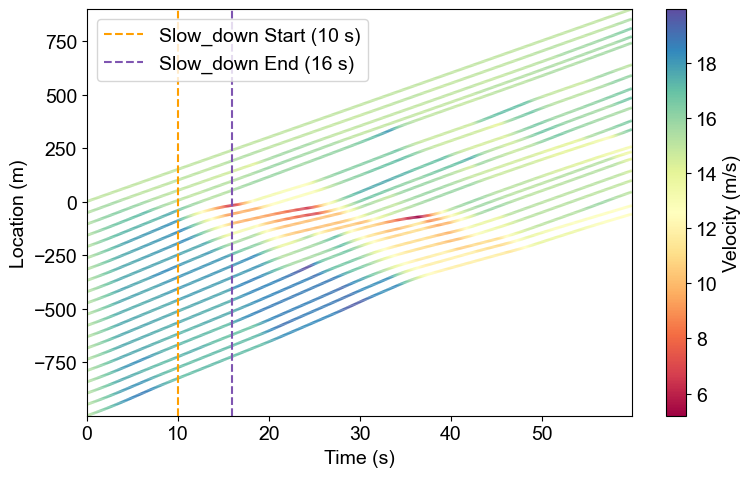

In [ ]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection

# 1) Path to the saved CSV (update this if needed)
filename = "simulation_timeseries_lambda_10000.csv"

# 2) Check that it exists
if not os.path.exists(filename):
    raise FileNotFoundError(
        f"File '{filename}' not found. Please update the `filename` to the correct path."
    )

# 3) Load the DataFrame
df = pd.read_csv(filename)

# 4) Unique vehicle IDs (e.g. 0..19)
vehicle_ids = df['vehicle_id'].unique()

# 5) Prepare the plot
plt.figure(figsize=(8, 5))
ax = plt.gca()

# 6) Colormap: velocity → color
cmap = plt.get_cmap('Spectral')
norm = plt.Normalize(df['velocity'].min(), df['velocity'].max())

# 7) Plot each vehicle’s trajectory colored by its velocity
for vid in vehicle_ids:
    subset = df[df['vehicle_id'] == vid]
    t = subset['time'].values
    x = subset['position'].values
    v = subset['velocity'].values

    # Build line segments: each segment is [(t[i], x[i]), (t[i+1], x[i+1])]
    points = np.array([t, x]).T.reshape(-1, 1, 2)
    segments = np.concatenate([points[:-1], points[1:]], axis=1)

    # Color each segment by the average velocity on that segment
    v_avg = (v[:-1] + v[1:]) / 2.0
    lc = LineCollection(segments, cmap=cmap, norm=norm, linewidth=2)
    lc.set_array(v_avg)
    ax.add_collection(lc)

# 8) Draw dashed vertical lines at t=10 and t=20 to mark slowdown
ax.axvline(10, color='#FF9F00', linestyle='--', linewidth=1.5, label='Slow_down Start (10 s)')
ax.axvline(16, color='#7F55B1', linestyle='--', linewidth=1.5, label='Slow_down End (16 s)')

# 9) Add colorbar (velocity → color)
cbar = plt.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=ax)
cbar.set_label('Velocity (m/s)')

# 10) Labels, title, legend
ax.set_xlabel('Time (s)')
ax.set_ylabel('Location (m)')
# ax.set_title('Vehicle Trajectories Colored by Velocity\n(Dashed lines at 10–20 s mark slowdown period)')
ax.legend(loc='upper left')

# 11) Set axis limits to cover full simulation
ax.set_xlim(df['time'].min(), df['time'].max())
ax.set_ylim(df['position'].min(), df['position'].max())

plt.tight_layout()
plt.savefig(
    "vehicle_trajectories_colored_by_velocity.pdf",
    dpi=300, bbox_inches='tight'
)
plt.show()


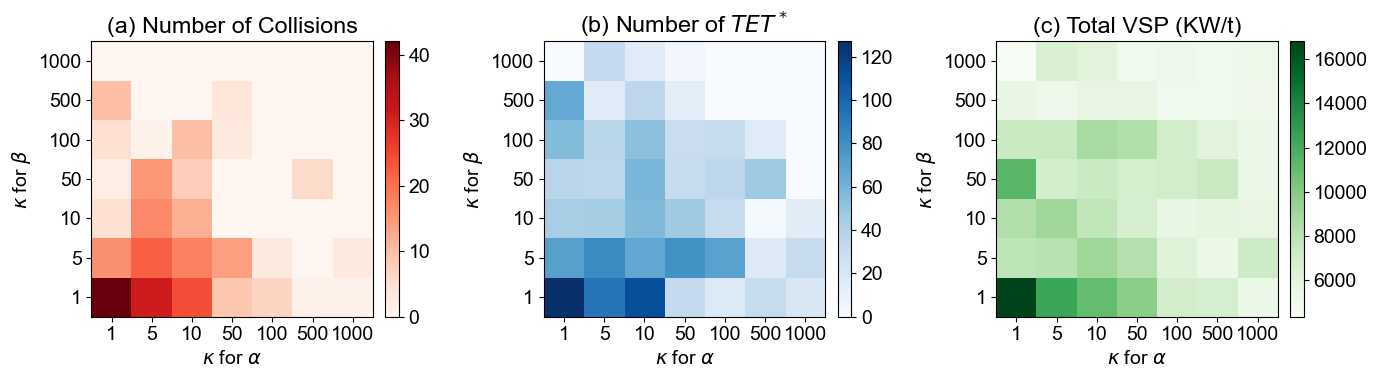

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1) Load your combined summary file
summary_file = "simulation_batch_results.csv"
df = pd.read_csv(summary_file)

plt.rc('font', family='Arial', size=14)

# 2) Sort the grid axes
kappas = np.sort(df['kappa'].unique())
pms    = np.sort(df['pm'].unique())

# 3) Pivot each indicator into a matrix
pivot_collisions = df.pivot(index='kappa', columns='pm', values='collisions').loc[kappas, pms]
pivot_warnings   = df.pivot(index='kappa', columns='pm', values='warnings').loc[kappas, pms]
pivot_vsp        = df.pivot(index='kappa', columns='pm', values='total_vsp').loc[kappas, pms]

# 4) Plotting
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharex=False, sharey=False)

cmap_specs = [
    (pivot_collisions, 'Reds',    "(a) Number of Collisions"),
    (pivot_warnings,   'Blues',   "(b) Number of $TET^*$"),
    (pivot_vsp,        'Greens',  "(c) Total VSP (KW/t)")
]

for ax, (pivot, cmap, title) in zip(axes, cmap_specs):
    im = ax.imshow(pivot, origin='lower', aspect='auto', cmap=cmap)
    ax.set_title(title)
    ax.set_xlabel(r"$\kappa$ for $\alpha$", fontsize=14)
    ax.set_ylabel(r"$\kappa$ for $\beta$", fontsize=14)
    # force ticks & labels on both axes
    ax.set_xticks(np.arange(len(pms)))
    ax.set_xticklabels(pms)
    ax.set_yticks(np.arange(len(kappas)))
    ax.set_yticklabels(kappas)
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

plt.tight_layout()
plt.savefig("indicator_heatmaps.pdf", dpi=300, bbox_inches='tight')
plt.show()
